# Principal Component Analysis (PCA) from Scratch

## 1. Overview and Intuition
**Principal Component Analysis (PCA)** is an unsupervised linear dimensionality reduction technique. It maps data from a high-dimensional space $\mathbb{R}^D$ into a lower-dimensional orthogonal subspace $\mathbb{R}^K$ ($K \le D$) such that the variance of the projected data is maximized and the reconstruction error is minimized.

### Mathematical Formulation
1. **Data Centering:**
   Compute the feature-wise empirical mean vector $\mu \in \mathbb{R}^D$:
   $$\mu = \frac{1}{N} \sum_{i=1}^N x_i$$
   Center the data: $\tilde{x}_i = x_i - \mu$.

2. **Sample Covariance Matrix:**
   The $D \times D$ sample covariance matrix $\Sigma$ is symmetric and positive semi-definite:
   $$\Sigma = \frac{1}{N - 1} \tilde{X}^T \tilde{X}, \quad \Sigma_{i, j} = \frac{1}{N - 1} \sum_{k=1}^N \tilde{x}_{k, i} \tilde{x}_{k, j}$$
   Since $\Sigma$ is symmetric, $\Sigma_{i, j} = \Sigma_{j, i}$.

3. **Power Iteration for Dominant Eigenvectors:**
   Rather than relying on a heavy numerical linear algebra solver (like full SVD), we compute the leading eigenvectors using **Power Iteration**:
   $$b_{k+1} = \frac{\Sigma b_k}{\|\Sigma b_k\|_2}$$
   As $k \to \infty$, $b_k$ converges to the leading eigenvector $v_1$, and the associated eigenvalue (variance) is given by the Rayleigh quotient:
   $$\lambda_1 = v_1^T \Sigma v_1$$

4. **Hotelling's Deflation (Subsequent Components):**
   To extract subsequent orthogonal eigenvectors ($v_2, v_3, \dots$), we deflate the matrix by subtracting the variance explained by the discovered component:
   $$\Sigma^{(m+1)} = \Sigma^{(m)} - \lambda_m v_m v_m^T$$
   Applying power iteration to $\Sigma^{(m+1)}$ directly yields the next principal axis $v_{m+1}$.

5. **Dimensionality Reduction (Projection):**
   Each centered point $\tilde{x}$ is projected onto the top $K$ principal components:
   $$z_i = \big[\tilde{x}_i \cdot v_1, \tilde{x}_i \cdot v_2, \dots, \tilde{x}_i \cdot v_K\big]$$

## 2. Implementation in Pure Python (Zero Dependencies)

In [2]:
import math
import random
from typing import List, Tuple


def dot_product(v1: List[float], v2: List[float]) -> float:
    """Computes inner product between two vectors."""
    return sum(a * b for a, b in zip(v1, v2))


def matrix_vector_mult(matrix: List[List[float]], vector: List[float]) -> List[float]:
    """Multiplies a (D x D) matrix by a (D x 1) vector."""
    return [dot_product(row, vector) for row in matrix]


def vector_norm(v: List[float]) -> float:
    """Computes Euclidean L2 norm of a vector."""
    return math.sqrt(sum(x ** 2 for x in v))


def compute_mean(X: List[List[float]]) -> List[float]:
    """Calculates empirical mean vector across samples."""
    num_samples = len(X)
    num_features = len(X[0])
    return [
        sum(X[row][col] for row in range(num_samples)) / num_samples
        for col in range(num_features)
    ]


def center_data(X: List[List[float]], mean_vector: List[float]) -> List[List[float]]:
    """Centers dataset by subtracting the mean vector."""
    return [[x - m for x, m in zip(sample, mean_vector)] for sample in X]


def compute_covariance_matrix(X_centered: List[List[float]]) -> List[List[float]]:
    """Computes symmetric (D x D) sample covariance matrix with Bessel's correction (N - 1)."""
    n_samples = len(X_centered)
    n_features = len(X_centered[0])
    cov = [[0.0] * n_features for _ in range(n_features)]

    for i in range(n_features):
        for j in range(i, n_features):
            cov_ij = sum(X_centered[k][i] * X_centered[k][j] for k in range(n_samples)) / (n_samples - 1)
            cov[i][j] = cov_ij
            cov[j][i] = cov_ij  # Exploiting covariance matrix symmetry

    return cov


def power_iteration(
    matrix: List[List[float]], max_iters: int = 150, tol: float = 1e-7
) -> Tuple[List[float], float]:
    """Finds leading eigenvector and eigenvalue using Power Iteration algorithm."""
    d = len(matrix)
    # Non-zero initial unit vector
    b_k = [1.0 / math.sqrt(d)] * d

    for _ in range(max_iters):
        b_next = matrix_vector_mult(matrix, b_k)
        norm = vector_norm(b_next)
        if norm < 1e-12:
            break
        b_next = [x / norm for x in b_next]

        # Check convergence: ||b_next - b_k|| < tol or antipodal ||b_next + b_k|| < tol
        diff = vector_norm([b1 - b0 for b1, b0 in zip(b_next, b_k)])
        if diff < tol:
            b_k = b_next
            break
        b_k = b_next

    # Compute eigenvalue lambda via Rayleigh quotient: b^T * M * b
    m_b = matrix_vector_mult(matrix, b_k)
    eigenvalue = dot_product(b_k, m_b)
    return b_k, eigenvalue


def pca(
    X: List[List[float]], n_components: int = 2
) -> Tuple[List[List[float]], List[List[float]], List[float], List[float]]:
    """Performs Principal Component Analysis from scratch.

    Returns:
        Tuple of (projected_data, components, explained_variances, mean_vector)
    """
    mean_vec = compute_mean(X)
    X_centered = center_data(X, mean_vec)
    cov_matrix = compute_covariance_matrix(X_centered)

    d = len(cov_matrix)
    components: List[List[float]] = []
    variances: List[float] = []

    # Deflation-based extraction of top n_components
    deflated_cov = [row[:] for row in cov_matrix]
    for _ in range(min(n_components, d)):
        v, eig_val = power_iteration(deflated_cov)
        components.append(v)
        variances.append(max(0.0, eig_val))

        # Hotelling's Deflation: M_next = M - lambda * v * v^T
        for r in range(d):
            for c in range(d):
                deflated_cov[r][c] -= eig_val * v[r] * v[c]

    # Project centered data onto selected principal components
    X_projected = [
        [dot_product(sample, comp) for comp in components]
        for sample in X_centered
    ]

    return X_projected, components, variances, mean_vec

## 3. Demonstration on 2D Correlated Synthetic Data

In [3]:
random.seed(42)

# Generate correlated 2D Gaussian points along line y = 1.6 * x
N = 80
X_raw: List[List[float]] = []
for _ in range(N):
    t = random.gauss(5.0, 2.0)
    noise = random.gauss(0.0, 0.6)
    X_raw.append([t, 1.6 * t + noise])

projected, principal_axes, variances, mu = pca(X_raw, n_components=2)

total_var = sum(variances)
print(f"Data Mean Vector: [{mu[0]:.3f}, {mu[1]:.3f}]")
for i, (axis, var) in enumerate(zip(principal_axes, variances), 1):
    ratio = (var / total_var * 100) if total_var > 0 else 0.0
    print(f"PC{i}: Axis = [{axis[0]:.4f}, {axis[1]:.4f}] | Eigenvalue = {var:.4f} ({ratio:.1f}% explained variance)")

Data Mean Vector: [5.336, 8.547]
PC1: Axis = [0.5256, 0.8507] | Eigenvalue = 12.5078 (99.3% explained variance)
PC2: Axis = [0.8507, -0.5256] | Eigenvalue = 0.0835 (0.7% explained variance)


## 4. Visualizing Principal Axes & 1D Projections with Matplotlib

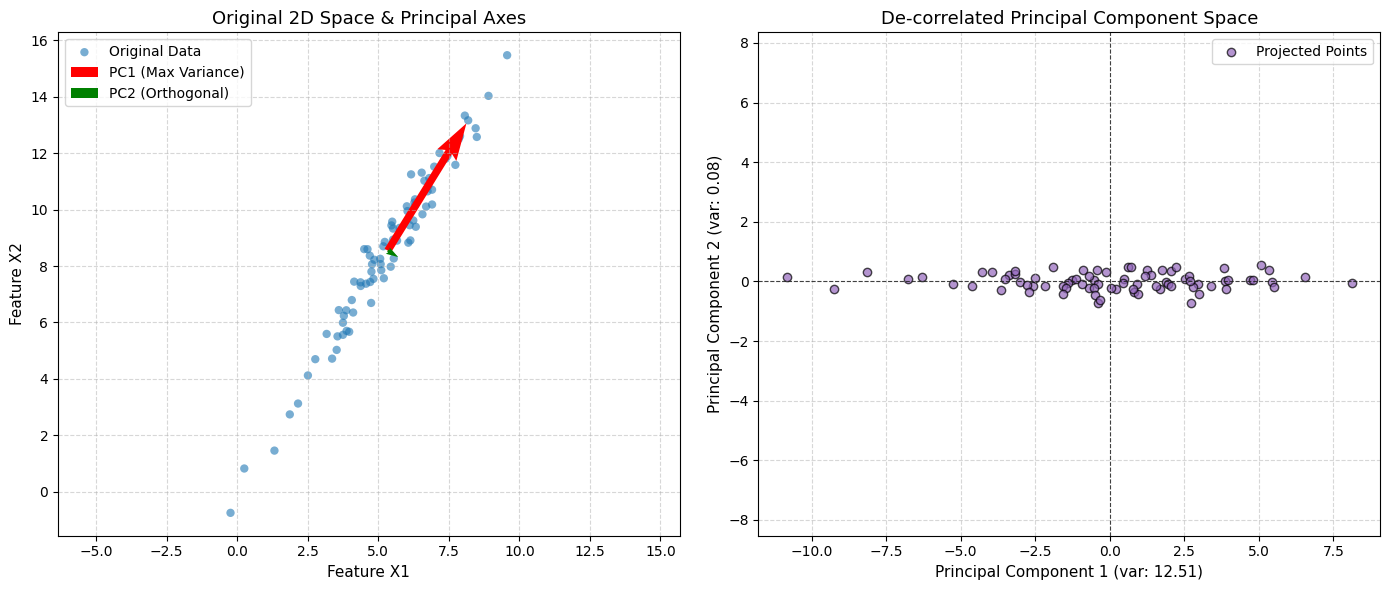

In [4]:
try:
    import matplotlib.pyplot as plt

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # 1. Original Data with Principal Component Vectors
    xs = [p[0] for p in X_raw]
    ys = [p[1] for p in X_raw]
    ax1.scatter(xs, ys, color="#1f77b4", alpha=0.6, edgecolors="none", label="Original Data")

    # Draw eigenvectors originating from mean
    scale_1 = math.sqrt(variances[0]) * 1.5
    scale_2 = math.sqrt(variances[1]) * 1.5
    ax1.quiver(mu[0], mu[1], principal_axes[0][0] * scale_1, principal_axes[0][1] * scale_1,
               angles="xy", scale_units="xy", scale=1, color="red", width=0.012, label="PC1 (Max Variance)")
    ax1.quiver(mu[0], mu[1], principal_axes[1][0] * scale_2, principal_axes[1][1] * scale_2,
               angles="xy", scale_units="xy", scale=1, color="green", width=0.012, label="PC2 (Orthogonal)")

    ax1.set_title("Original 2D Space & Principal Axes", fontsize=13)
    ax1.set_xlabel("Feature X1", fontsize=11)
    ax1.set_ylabel("Feature X2", fontsize=11)
    ax1.axis("equal")
    ax1.legend()
    ax1.grid(True, linestyle="--", alpha=0.5)

    # 2. Transformed Coordinates along Principal Components
    pc1_coords = [p[0] for p in projected]
    pc2_coords = [p[1] for p in projected]
    ax2.scatter(pc1_coords, pc2_coords, color="#9467bd", alpha=0.7, edgecolors="k", label="Projected Points")
    ax2.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
    ax2.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
    ax2.set_title("De-correlated Principal Component Space", fontsize=13)
    ax2.set_xlabel(f"Principal Component 1 (var: {variances[0]:.2f})", fontsize=11)
    ax2.set_ylabel(f"Principal Component 2 (var: {variances[1]:.2f})", fontsize=11)
    ax2.axis("equal")
    ax2.legend()
    ax2.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib is not installed in the environment. Skipping visual plot.")